In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"minimum_profit": np.inf, "minimum_loss": 0.0},
    "Default": {},
    "Experimental1": {"cooldown_long": 180.0, "cooldown_short": 90.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices

,BTC,ETH,XRP,BNB,ADA,SOL,DOGE,DOT,LTC,LINK,...,XVG,BCN,NXT,PPC,NMC,DGB,SC,QTUM,ICX,LSK
Date,,,,,,,,,,,,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.058550,NaN,...,NaN,NaN,NaN,1.540270,1.264560,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.685230,NaN,...,NaN,NaN,NaN,1.685280,1.229760,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.327770,NaN,...,NaN,NaN,NaN,1.216330,1.104190,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.286440,NaN,...,NaN,NaN,NaN,1.641050,1.194410,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.245920,NaN,...,NaN,NaN,NaN,1.488790,1.110980,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,1.334452,740.823608,0.223782,106.422340,0.081809,1.149771,61.531612,12.320927,...,0.002583,0.000059,NaN,0.446449,1.317299,0.003360,0.000820,0.877745,0.009176,0.197685
2026-10-21,84011.968750,2470.766113,1.363619,745.868347,0.224979,106.793655,0.081867,1.141323,61.454342,12.484719,...,0.002605,0.000037,NaN,0.343409,1.176803,0.003399,0.000850,0.889200,0.008703,0.196787
2026-10-22,81311.890625,2386.189209,1.307656,730.476624,0.212025,103.542320,0.078676,1.111869,58.756485,11.943166,...,0.002455,0.000029,NaN,0.342047,1.535211,0.003527,0.000893,0.852186,0.009433,0.183983


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 3/3 [02:09<00:00, 43.09s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,MDD,Survival,RoAC,iteration
0,BuyHold,DOGE,2059,0,2695,2059,2695,55,-5420,48.000000,41,1
1,BuyHold,BCH,2069,0,1821,2069,1821,45,-4245,118.000000,11,1
2,BuyHold,LSK,2069,0,750,2069,750,21,-2478,47.666667,-20,1
3,BuyHold,WAVES,2069,0,1717,2069,1717,72,-33927,242.500000,358,1
4,BuyHold,FTT,2059,0,930,2059,930,14,-2242,144.000000,-33,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2837,Experimental1,FTT,3257,0,1326,3257,1326,22,-3598,130.666667,-14,100
2838,Experimental1,VET,2316,11244,1084,838,12329,86,-17451,84.000000,433,100
2839,Experimental1,SOL,2583,8903,2271,527,11174,70,-2999,86.000000,136,100
2840,Experimental1,REP,2722,1998,1485,2153,3484,52,-2221,0.000000,49,100


In [7]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC_mean=("RoAC", "mean"),
    RoAC_median=("RoAC", "median"),
    MDD_mean=("MDD", "mean"),
    MDD_median=("MDD", "median"),
    Portfolio_mean=("Portfolio", "mean"),
    Portfolio_median=("Portfolio", "median"),
    Cash_spent_mean=("Cash_spent", "mean"),
    Cash_spent_median=("Cash_spent", "median"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD_mean'] / compare_res['Total_value_mean']
compare_res['Profit_coef'] = compare_res['Total_value_mean'] / compare_res['Cash_spent_mean']
compare_res.sort_values("RoAC_mean", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC_mean,RoAC_median,MDD_mean,MDD_median,Portfolio_mean,Portfolio_median,Cash_spent_mean,Cash_spent_median,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle,Profit_coef
strategy,,,,,,,,,,,,,,
BuyHold,135.49,27.00,-13035.95,-4175.50,3899.73,1740.50,2064.68,2069.00,3899.73,1740.50,1029.75,3436.00,-3.34,1.89
Experimental1,112.74,51.00,-4981.81,-2969.50,1694.14,1471.50,2685.57,2583.00,5451.02,4063.00,2329.00,6379.50,-0.91,2.03
Default,89.63,60.00,-3128.33,-1975.00,1394.95,1156.50,2702.28,2583.00,5291.88,4401.00,2839.50,6231.00,-0.59,1.96


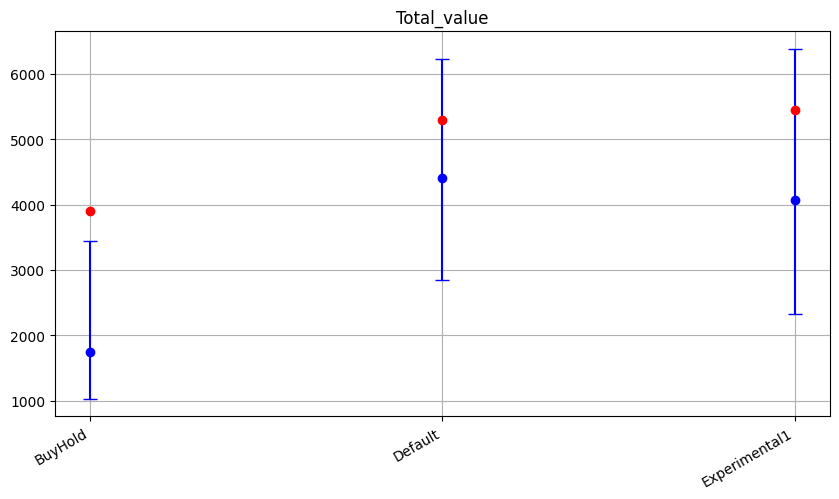

In [8]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()